In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

In [2]:
env = gym.make('FrozenLake-v1')

#parameters
alpha = 0.1
gamma = 0.99
epsilon = 1
min_epsilon = 0.01
epsilon_decay = 0.9995

num_episodes = 10000

#q-table
Q = np.zeros([env.observation_space.n, env.action_space.n])

rewards_list = []

In [3]:
for i in range(num_episodes):
    state, info = env.reset()
    done = False
    episode_reward = 0

    while not done:
        #epsilon-greedy to choose action
        if np.random.uniform() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(Q[state, :])

        #observe new state and reward
        new_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        #temporal-difference policy update
        Q[state, action] = Q[state, action] + alpha * (reward + gamma * np.max(Q[new_state, :]) - Q[state, action])
        
        state = new_state
        episode_reward += reward

    epsilon = max(min_epsilon, epsilon * epsilon_decay)
    rewards_list.append(episode_reward)

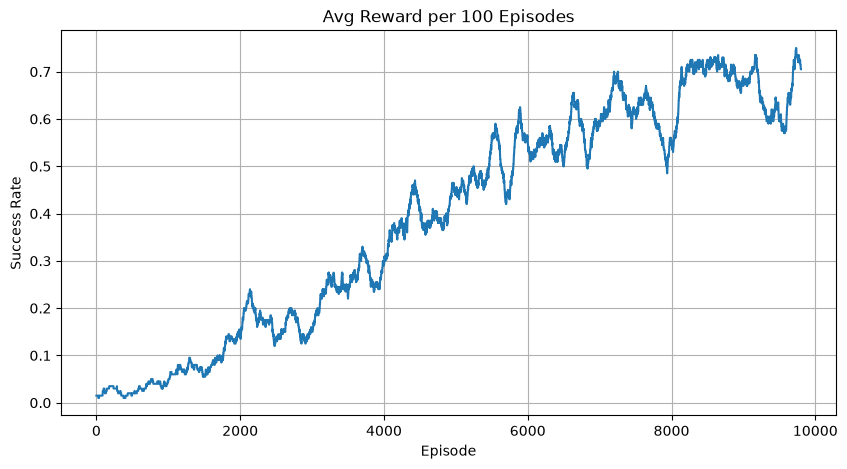

In [4]:
window = 200
moving_avg = np.convolve(rewards_list, np.ones(window)/window, mode='valid')

plt.figure(figsize=(10,5))
plt.plot(moving_avg)
plt.title('Avg Reward per 100 Episodes')
plt.xlabel('Episode')
plt.ylabel('Success Rate')
plt.grid(True)
plt.show()